# 3 · Backstripping the Coastal Range, Taiwan

**What.** 1-D Airy backstripping of the northern (N) and southern (S) Coastal Range composite sections with Monte Carlo uncertainty.

**Why.** Separate how much the basin floor sank because of tectonics (plate flexure/collision) from how much is just the weight of sediment and water.

**Equations** (Lai et al. 2022; Watts 2001).

Decompaction — the solid (grain) thickness of a unit is conserved when it is moved up:

$$G = \int_{z_1}^{z_2}(1-\phi(z))\,dz = (z_2-z_1) - \phi_0 c\,(e^{-z_1/c}-e^{-z_2/c})$$

Bulk sediment density: $\rho_s = \dfrac{\sum_i [\phi_i\rho_w + (1-\phi_i)\rho_{g,i}]\,T_i}{\sum_i T_i}$

Airy tectonic subsidence:

$$\zeta = S\,\frac{\rho_a-\rho_s}{\rho_a-\rho_w} + W - \Delta SL\,\frac{\rho_a}{\rho_a-\rho_w}$$

| symbol | meaning |
|---|---|
| z₁, z₂ | top/base depth of a unit below seafloor (m) |
| φ₀, c | porosity–depth constants (notebook 1) |
| G | solid thickness (m) |
| T_i | decompacted thickness (m) |
| ρ_w, ρ_g, ρ_a | water, grain and asthenosphere density (kg m⁻³) |
| S | decompacted sediment thickness (total subsidence of basement) (m) |
| W | paleo-water depth (notebook 2) (m) |
| ΔSL | sea level relative to today (Miller et al. 2020) (m) |
| ζ | tectonic (water-loaded) subsidence (m) |

**Uncertainty.** Every input (age, thickness, water depth, sea level, φ₀, c, densities) is drawn from a normal distribution, n = 2000 times, and the backstrip is rerun. Bands are 16–84 % and 2.5–97.5 %. The original R code used the first-order delta method; that is kept in `pybasinsubs.legacy` (notebook 4).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs.column import from_basinsubs, MAX_ELEV_M
from pybasinsubs.backstrip import backstrip
from pybasinsubs.plotting import geohistory
res = {}
for reg in "NS":
    col = from_basinsubs(reg)
    res[reg] = backstrip(col, n=2000, seed=1)
col.units.head()

,unit,age_top_Ma,age_top_err_Ma,thickness_m,thickness_err_m,water_depth_m,water_depth_err_m,sea_level_m,sea_level_err_m,f_mudstone,f_sandstone_tw,f_marine_avg,eroded,eroded_at_Ma,water_depth_at_erosion_m,age_base_Ma
0,0,0.605598,0.023165,750.000000,250.000000,457.796985,457.796985,-56.005000,5.455434,0.500000,0.500000,0.0,1,NaN,0.0,0.820021
1,1,0.820021,0.018103,613.746033,143.840129,915.593971,274.832899,-38.761000,4.096201,0.317878,0.682122,0.0,0,NaN,0.0,1.018000
2,2,1.018000,0.002000,698.687236,145.320347,722.541814,139.432729,-30.791111,4.809581,0.176839,0.823161,0.0,0,NaN,0.0,1.180000
3,3,1.180000,0.001000,89.001999,36.757082,742.102106,120.886209,-18.945000,7.006365,0.247914,0.752086,0.0,0,NaN,0.0,1.215000
4,4,1.215000,0.011000,132.774379,39.113254,749.118539,114.038823,-22.303636,4.491615,0.375000,0.625000,0.0,0,NaN,0.0,1.231000


## 1 · Preserved stratigraphy and paleo-water inputs

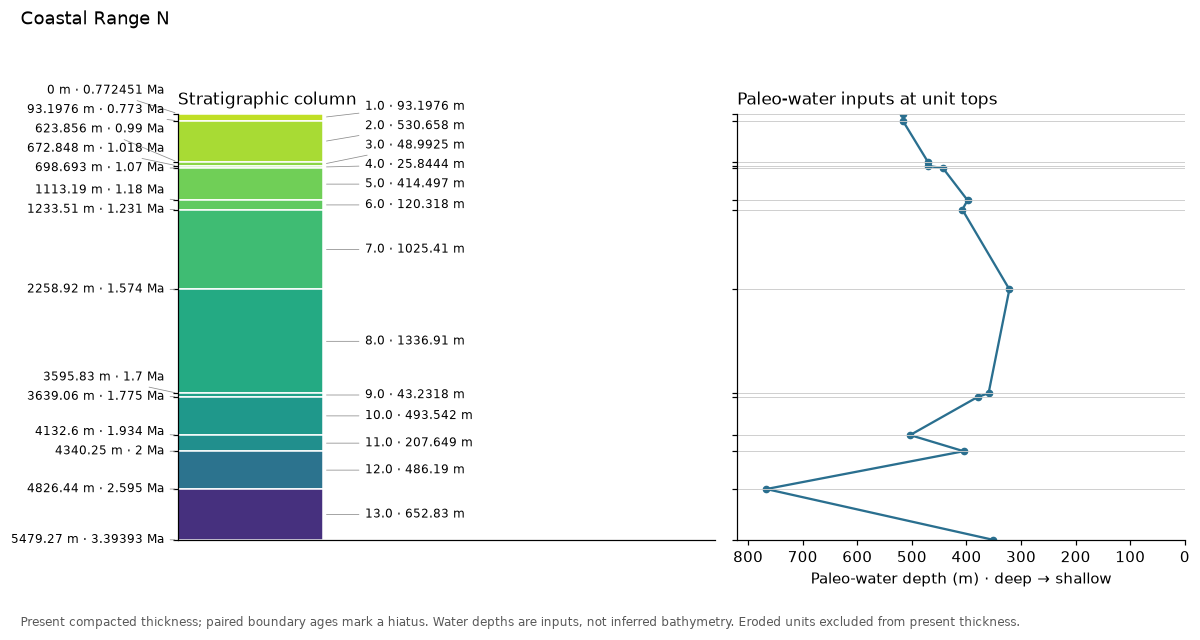

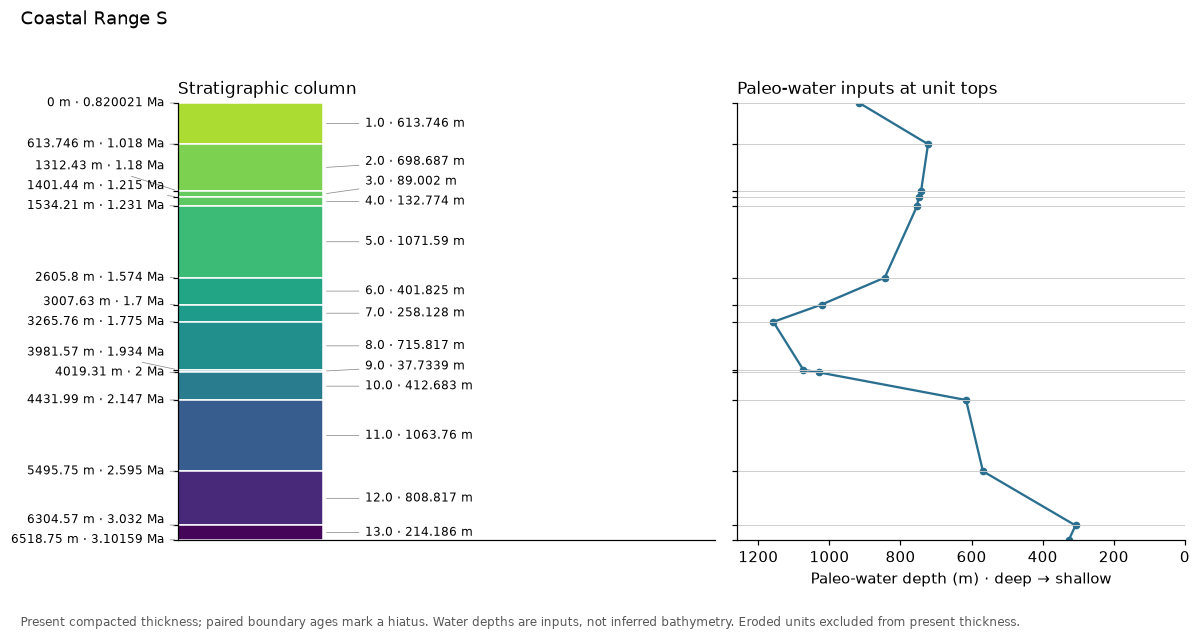

In [3]:
%matplotlib inline
from pybasinsubs.input_plots import stratigraphic_column, compaction_relations, interpreted_section
from IPython.display import display
import matplotlib.pyplot as plt
plt.ioff()
for reg in "NS":
    fig = stratigraphic_column(res[reg].column)
    display(fig); plt.close(fig)


## 2 · Compaction relations used

The published sampled curves and fitting evidence are in notebook 1; they are not measured porosity points from these composite columns.

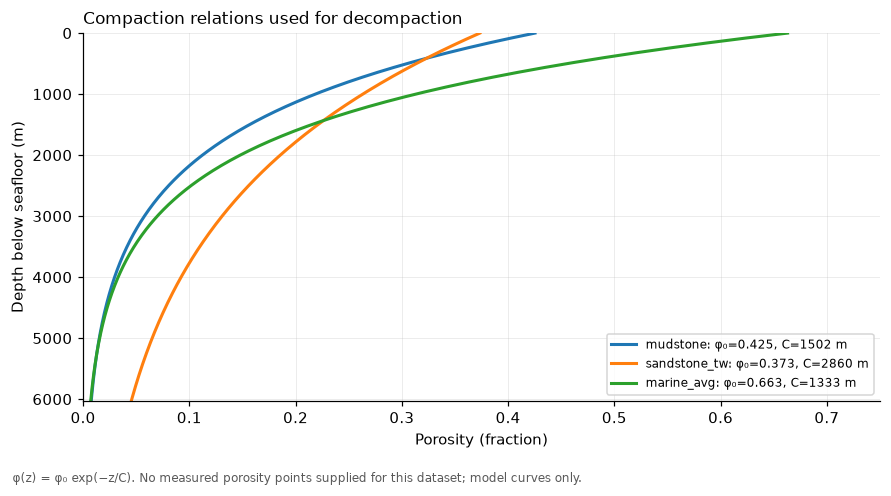

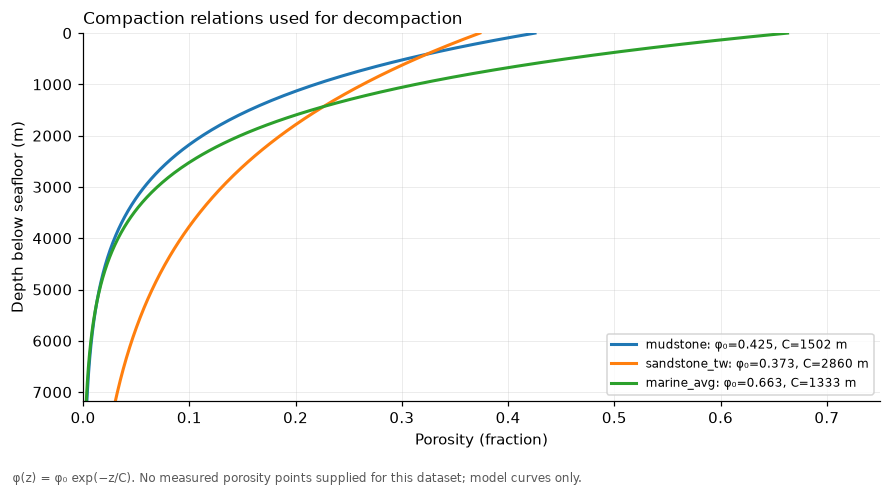

In [4]:
for reg in "NS":
    fig = compaction_relations(res[reg].column)
    display(fig); plt.close(fig)


## 3 · Geohistory and tables

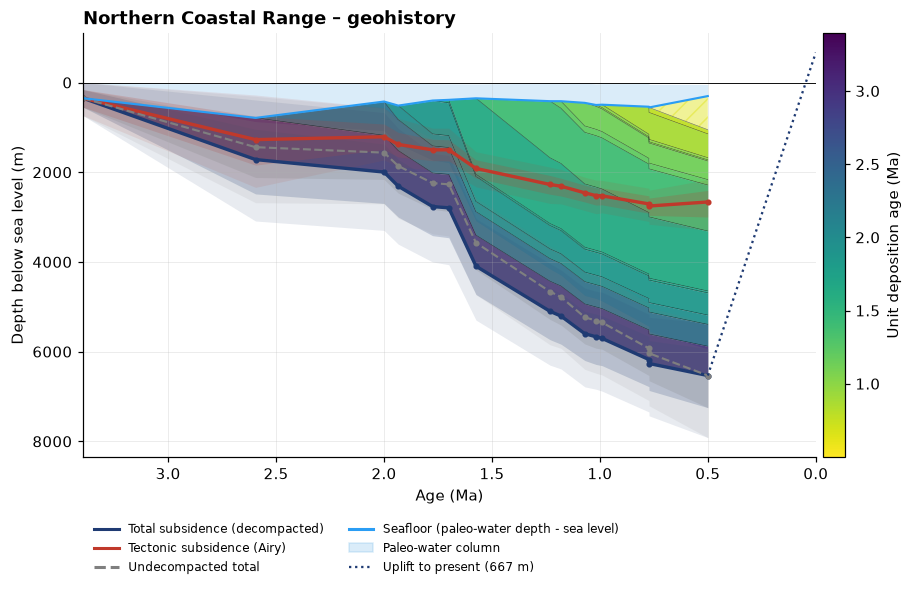

,node,age_Ma,undecompacted_total_m,undecompacted_total_m_sd,undecompacted_total_m_p2.5,undecompacted_total_m_p16,undecompacted_total_m_p50,undecompacted_total_m_p84,undecompacted_total_m_p97.5,total_subsidence_m,...,water_depth_m_p84,water_depth_m_p97.5,sea_level_m,sea_level_m_sd,sea_level_m_p2.5,sea_level_m_p16,sea_level_m_p50,sea_level_m_p84,sea_level_m_p97.5,age_Ma_sd
0,14,3.39,349.49,191.16,-1.05,159.25,351.74,551.27,739.87,349.49,...,553.70,743.22,1.81,1.21,-0.49,0.63,1.92,3.05,4.11,0.17
1,13,2.60,1441.75,617.80,308.29,870.99,1480.84,2117.60,2679.07,1718.03,...,1274.38,1740.52,-22.23,4.24,-30.84,-26.50,-22.24,-18.07,-14.04,0.01
2,12,2.00,1563.47,540.98,571.89,1074.22,1594.20,2159.91,2704.24,1996.43,...,458.33,507.41,-19.27,1.86,-23.01,-21.18,-19.21,-17.40,-15.72,0.00
3,11,1.93,1861.25,547.19,860.39,1373.90,1891.85,2466.33,3023.48,2312.60,...,583.70,660.41,-11.34,5.83,-23.16,-17.01,-11.35,-5.57,0.40,0.00
4,10,1.78,2242.52,549.39,1249.34,1730.12,2258.48,2827.86,3372.60,2765.79,...,439.48,495.10,-23.69,2.94,-29.60,-26.59,-23.63,-20.75,-18.09,0.01
5,9,1.70,2270.19,550.25,1267.31,1786.51,2299.87,2874.26,3420.68,2794.06,...,415.17,473.73,-27.14,4.20,-35.63,-31.27,-27.20,-23.06,-19.10,0.00
6,8,1.57,3572.80,553.78,2572.34,3083.58,3602.66,4175.27,4729.08,4094.86,...,381.64,436.47,-30.99,3.01,-36.89,-34.10,-31.17,-28.03,-25.19,0.00
7,7,1.23,4662.20,561.72,3641.09,4156.22,4686.22,5280.84,5846.98,5101.74,...,512.28,612.49,-8.77,3.32,-15.26,-12.04,-8.59,-5.35,-2.26,0.00
8,6,1.18,4783.04,556.25,3781.31,4295.21,4804.47,5407.93,5926.85,5207.50,...,488.14,574.82,-18.94,7.05,-32.79,-25.73,-18.93,-11.82,-5.06,0.00
9,5,1.07,5234.60,553.77,4232.25,4748.12,5254.59,5827.92,6394.47,5600.64,...,500.69,552.10,-10.70,6.32,-22.60,-17.23,-10.65,-4.36,1.94,0.00


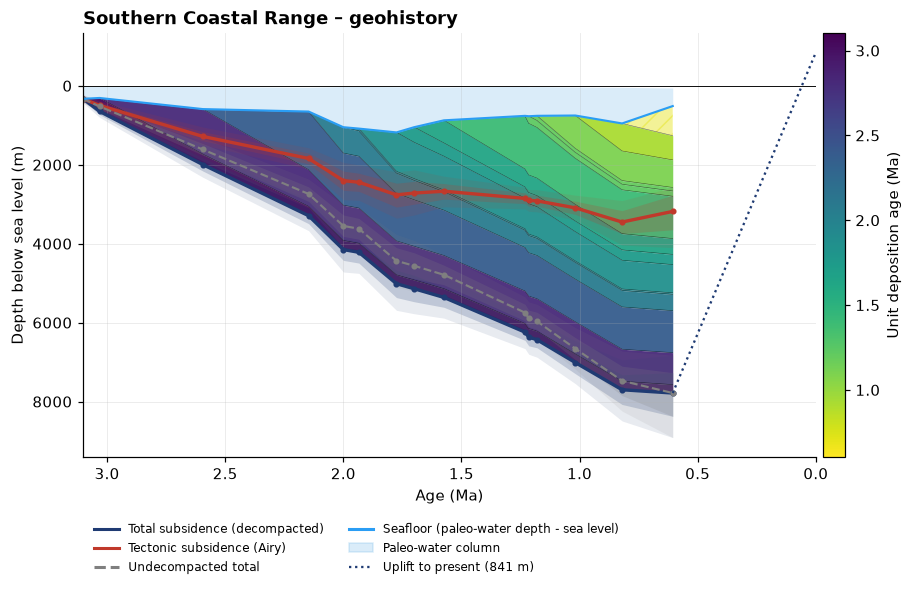

,node,age_Ma,undecompacted_total_m,undecompacted_total_m_sd,undecompacted_total_m_p2.5,undecompacted_total_m_p16,undecompacted_total_m_p50,undecompacted_total_m_p84,undecompacted_total_m_p97.5,total_subsidence_m,...,water_depth_m_p84,water_depth_m_p97.5,sea_level_m,sea_level_m_sd,sea_level_m_p2.5,sea_level_m_p16,sea_level_m_p50,sea_level_m_p84,sea_level_m_p97.5,age_Ma_sd
0,14,3.10,330.53,50.63,227.73,281.71,331.54,382.04,430.95,330.53,...,378.02,426.43,-4.21,2.58,-9.12,-6.72,-3.99,-1.56,0.70,0.03
1,13,3.03,522.90,63.10,398.07,464.07,525.94,589.88,643.62,647.90,...,354.75,398.01,-1.09,2.86,-6.88,-3.96,-1.09,1.71,4.43,0.01
2,12,2.60,1613.23,148.98,1318.94,1461.89,1614.10,1757.98,1903.61,1995.22,...,662.75,750.24,-22.23,4.19,-30.63,-26.52,-22.11,-18.03,-14.26,0.01
3,11,2.15,2739.94,189.29,2364.02,2560.87,2746.79,2929.23,3096.14,3290.46,...,737.32,853.39,-37.61,5.66,-49.09,-43.12,-37.62,-32.01,-26.20,0.00
4,10,2.00,3548.78,275.82,3015.97,3272.03,3548.83,3814.45,4098.75,4148.25,...,1272.90,1494.79,-19.27,1.87,-23.03,-21.12,-19.23,-17.41,-15.71,0.00
5,9,1.93,3621.85,263.53,3083.83,3360.32,3620.02,3887.78,4152.92,4218.61,...,1294.07,1526.69,-11.34,5.74,-22.94,-16.97,-11.41,-5.76,-0.36,0.00
6,8,1.78,4434.41,339.55,3766.88,4101.22,4435.80,4785.55,5109.42,5013.42,...,1459.91,1735.20,-23.69,3.07,-29.70,-26.85,-23.87,-20.67,-17.78,0.02
7,7,1.70,4560.14,332.06,3917.42,4229.93,4562.25,4881.45,5199.05,5140.87,...,1307.50,1581.13,-27.14,4.12,-35.17,-31.19,-26.91,-22.90,-19.08,0.00
8,6,1.57,4788.23,253.38,4281.62,4545.29,4797.28,5041.07,5297.94,5361.07,...,1037.83,1223.97,-30.99,2.93,-36.74,-33.81,-30.98,-28.03,-25.22,0.00
9,5,1.23,5746.46,208.84,5347.15,5534.42,5736.00,5952.89,6170.72,6239.88,...,870.44,975.56,-8.77,3.38,-15.14,-12.27,-8.75,-5.38,-2.01,0.00


In [5]:
for reg, name in [("N", "Northern"), ("S", "Southern")]:
    fig, ax = plt.subplots(figsize=(9, 5))
    geohistory(res[reg], ax=ax, title=f"{name} Coastal Range – geohistory", present_elevation=MAX_ELEV_M[reg] / 2)
    display(fig); plt.close(fig)
    display(res[reg].summary().round(2))

**How to read the geohistory diagrams.** Time runs left (old) to right (now). Each coloured band is one stratigraphic unit, coloured by its age; it starts as a thin wedge at the seafloor when it is deposited and gets thinner (compacted) as it is buried.

- **Dark blue line**: depth of the base of the section (total subsidence, decompacted). Grey shading is its uncertainty.
- **Dashed grey**: the same thing without decompaction — always shallower, the gap is the compaction correction.
- **Red line**: tectonic subsidence — the part not caused by sediment and water loading. Red shading is its uncertainty.
- **Light blue**: the seafloor (paleo-water depth corrected for sea level).
- **Dotted line**: the jump from the youngest unit to its present elevation (half the maximum elevation, as in the paper), i.e. late uplift.

**Reading.** Both regions sank fast (several km in ~2 Myr), with the fastest tectonic subsidence before ~1.5 Ma, then were uplifted to above sea level in the last ~0.5 Myr — the record of a forearc basin being pulled down and then accreted in the arc–continent collision.

## 4 · Thermal history

No heat flow is specified for these composite sections. Notebook 6 demonstrates thermal plots and tables for wells with documented heat-flow constraints.

### Lithology sensitivity

The R code used the lithology of the **first row** of the litho table for every unit (a bug kept for parity in the legacy layer). The generic engine uses each unit's own lithology by default. The difference in total subsidence:

max |Δ total subsidence| = 43 m
saved image/nb3_lithology_sensitivity_N.png


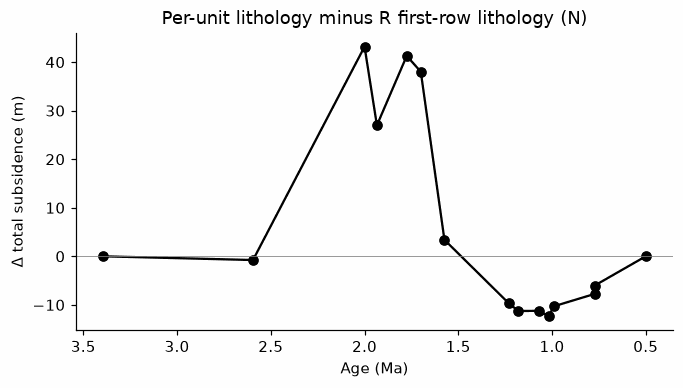

In [5]:
r_bug = backstrip(from_basinsubs("N", litho_mode="r_first_row"), n=0, mc=False)
r_ok = backstrip(from_basinsubs("N"), n=0, mc=False)
d = r_ok.summary().total_subsidence_m - r_bug.summary().total_subsidence_m
print(f"max |Δ total subsidence| = {abs(d).max():.0f} m")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(r_ok.summary().age_Ma, d, "o-", color="k"); ax.axhline(0, color="grey", lw=.5)
ax.invert_xaxis(); ax.set_xlabel("Age (Ma)"); ax.set_ylabel("Δ total subsidence (m)")
ax.set_title("Per-unit lithology minus R first-row lithology (N)")
save(fig, "nb3_lithology_sensitivity_N.png"); plt.show()

**Reading.** Positive values mean the per-unit lithology gives *more* decompacted subsidence. The difference is up to a few tens of metres — small compared with the water-depth uncertainty (hundreds of metres), so the paper's conclusions do not change.